--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Beverage_category          242 non-null    object 
 1   Beverage                   242 non-null    object 
 2   Beverage_prep              242 non-null    object 
 3   Calories                   242 non-null    int64  
 4    Total Fat (g)             242 non-null    object 
 5   Trans Fat (g)              242 non-null    float64
 6   Saturated Fat (g)          242 non-null    float64
 7    Sodium (mg)               242 non-null    int64  
 8    Total Carbohydrates (g)   242 non-null    int64  
 9   Cholesterol (mg)           242 non-null    int64  
 10   Dietary Fibre (g)         242 non-null    int64  
 11   Sugars (g)                242 non-null    int64  
 12   Protein (g)               242 non-null    float64
 13  Vitamin A (% DV)           24

,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75



--- Missing Values ---
Beverage_category            0
Beverage                     0
Beverage_prep                0
Calories                     0
 Total Fat (g)               0
Trans Fat (g)                0
Saturated Fat (g)            0
 Sodium (mg)                 0
 Total Carbohydrates (g)     0
Cholesterol (mg)             0
 Dietary Fibre (g)           0
 Sugars (g)                  0
 Protein (g)                 0
Vitamin A (% DV)             0
Vitamin C (% DV)             0
 Calcium (% DV)              0
Iron (% DV)                  0
Caffeine (mg)                1
dtype: int64

--- Generating Pie Charts for: Beverage_category, Beverage, Beverage_prep,  Total Fat (g), Saturated Fat (g),  Sodium (mg),  Dietary Fibre (g), Vitamin A (% DV) , Vitamin C (% DV),  Calcium (% DV) , Iron (% DV) , Caffeine (mg) ---


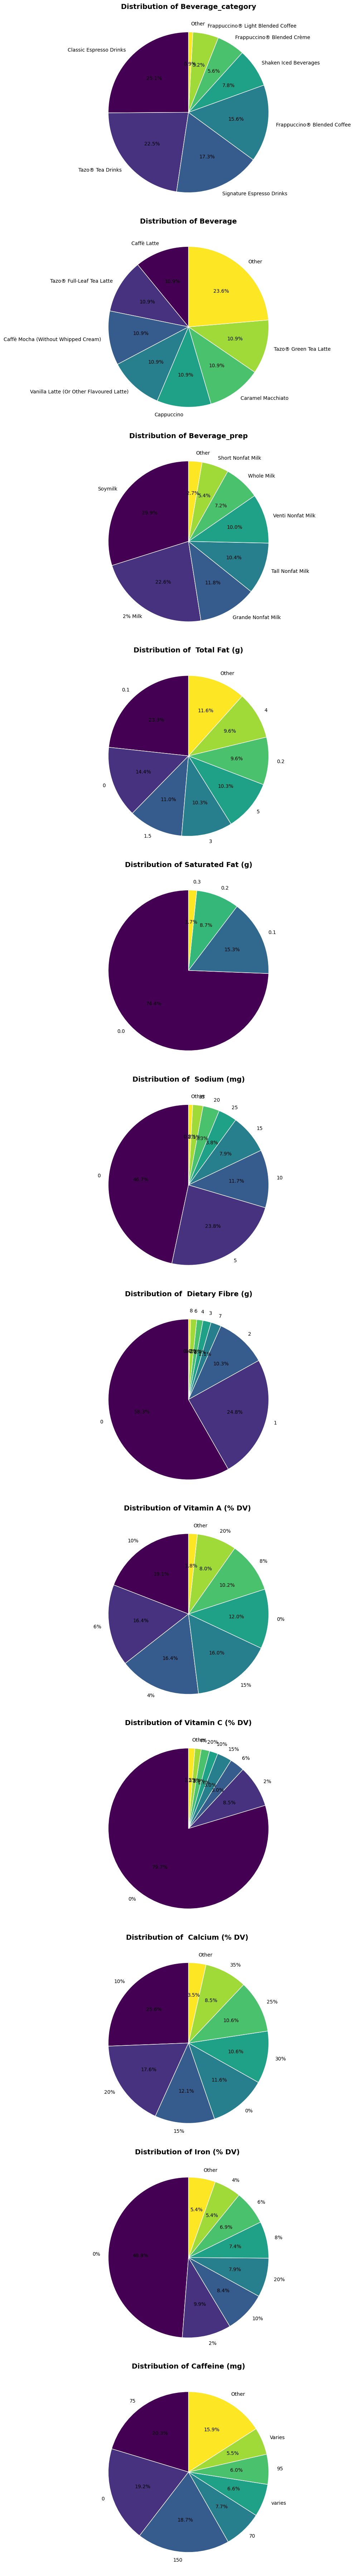

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/starbucks.csv')

# Display basic information
print("--- Dataset Info ---")
print(df.info())
print("\n--- First 5 Rows ---")
display(df.head())
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Identify categorical columns to plot pie charts
# We will filter for columns with a reasonable number of unique values (e.g., between 2 and 10)
cat_cols = [col for col in df.columns if df[col].dtype == 'object' or df[col].nunique() <= 10]

if len(cat_cols) > 0:
    print(f"\n--- Generating Pie Charts for: {', '.join(cat_cols)} ---")
    fig, axes = plt.subplots(len(cat_cols), 1, figsize=(8, 6 * len(cat_cols)))
    if len(cat_cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, cat_cols):
        value_counts = df[col].value_counts()
        # Limit to top 8 categories if there are too many
        if len(value_counts) > 8:
            value_counts = value_counts.head(7)
            value_counts['Other'] = df[col].nunique() - 7

        value_counts.plot.pie(
            autopct='%1.1f%%',
            startangle=90,
            ax=ax,
            cmap='viridis',
            wedgeprops={'edgecolor': 'white'}
        )
        ax.set_title(f'Distribution of {col}', fontsize=14, fontweight='bold')
        ax.set_ylabel('')

    plt.tight_layout()
    plt.show()
else:
    print("\nNo suitable categorical columns found for pie charts. Let's plot distribution of numerical columns instead.")
    df.hist(figsize=(10, 8))
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean and prepare data
model_df = df.copy()

# Strip whitespaces from column names
model_df.columns = model_df.columns.str.strip()

# Clean object columns that should be numerical (remove % and whitespace)
clean_cols = ['Total Fat (g)', 'Vitamin A (% DV)', 'Vitamin C (% DV)', 'Calcium (% DV)', 'Iron (% DV)', 'Caffeine (mg)']
for col in clean_cols:
    if col in model_df.columns:
        model_df[col] = model_df[col].astype(str).str.replace('%', '').str.strip()
        # Convert 'Varies' or invalid values to NaN, then fill with 0
        model_df[col] = pd.to_numeric(model_df[col], errors='coerce').fillna(0)

# Set our target (Beverage_category) and numerical features
target_col = 'Beverage_category'
feature_cols = ['Calories', 'Total Fat (g)', 'Trans Fat (g)', 'Saturated Fat (g)', 'Sodium (mg)',
                'Total Carbohydrates (g)', 'Cholesterol (mg)', 'Dietary Fibre (g)', 'Sugars (g)',
                'Protein (g)', 'Vitamin A (% DV)', 'Vitamin C (% DV)', 'Calcium (% DV)', 'Iron (% DV)', 'Caffeine (mg)']

X = model_df[feature_cols]
le = LabelEncoder()
y = le.fit_transform(model_df[target_col])

# 2. Split into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (193, 15)
Testing set shape: (49, 15)


In [ ]:
# 3. Train the Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# 4. Make predictions
y_pred = clf.predict(X_test)

# 5. Output Accuracy and Classification Report
accuracy = accuracy_score(y_test, y_pred)
print(f"Decision Tree Model Accuracy: {accuracy * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Decision Tree Model Accuracy: 71.43%

--- Classification Report ---
                                   precision    recall  f1-score   support

          Classic Espresso Drinks       0.56      0.83      0.67        12
                           Coffee       0.00      0.00      0.00         1
      Frappuccino® Blended Coffee       0.88      1.00      0.93         7
       Frappuccino® Blended Crème       0.75      1.00      0.86         3
Frappuccino® Light Blended Coffee       0.00      0.00      0.00         2
            Shaken Iced Beverages       0.80      1.00      0.89         4
        Signature Espresso Drinks       0.00      0.00      0.00         8
                        Smoothies       1.00      1.00      1.00         2
                 Tazo® Tea Drinks       0.82      0.90      0.86        10

                         accuracy                           0.71        49
                        macro avg       0.53      0.64      0.58        49
                     weighted 

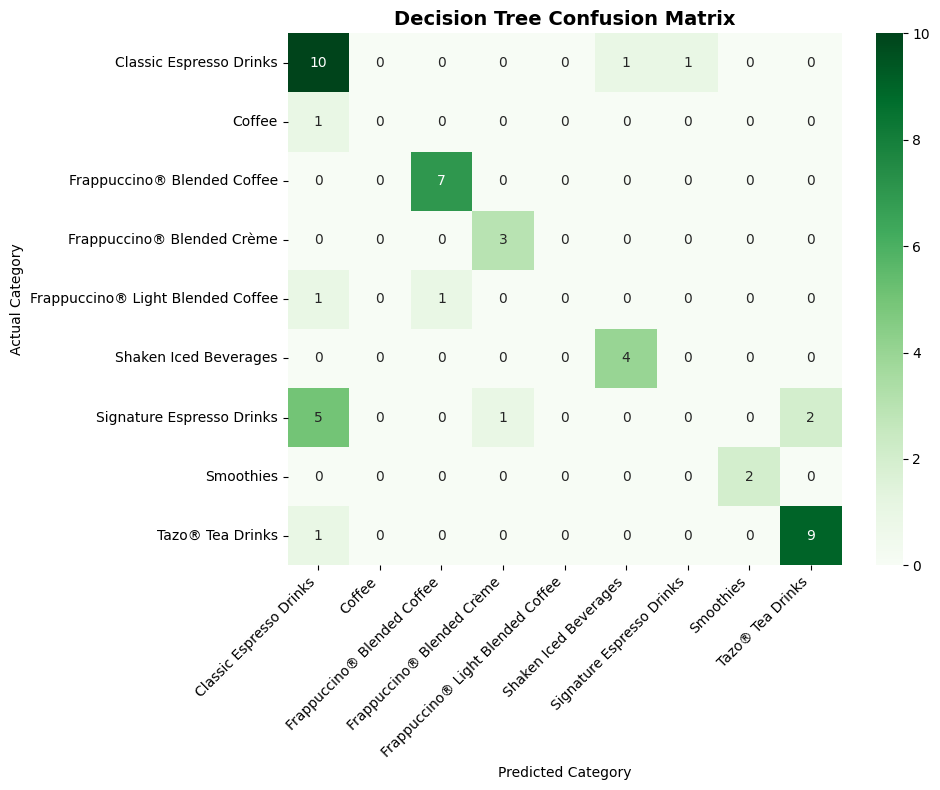

In [ ]:
# 6. Visualize model results with a Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Greens')
plt.title('Decision Tree Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

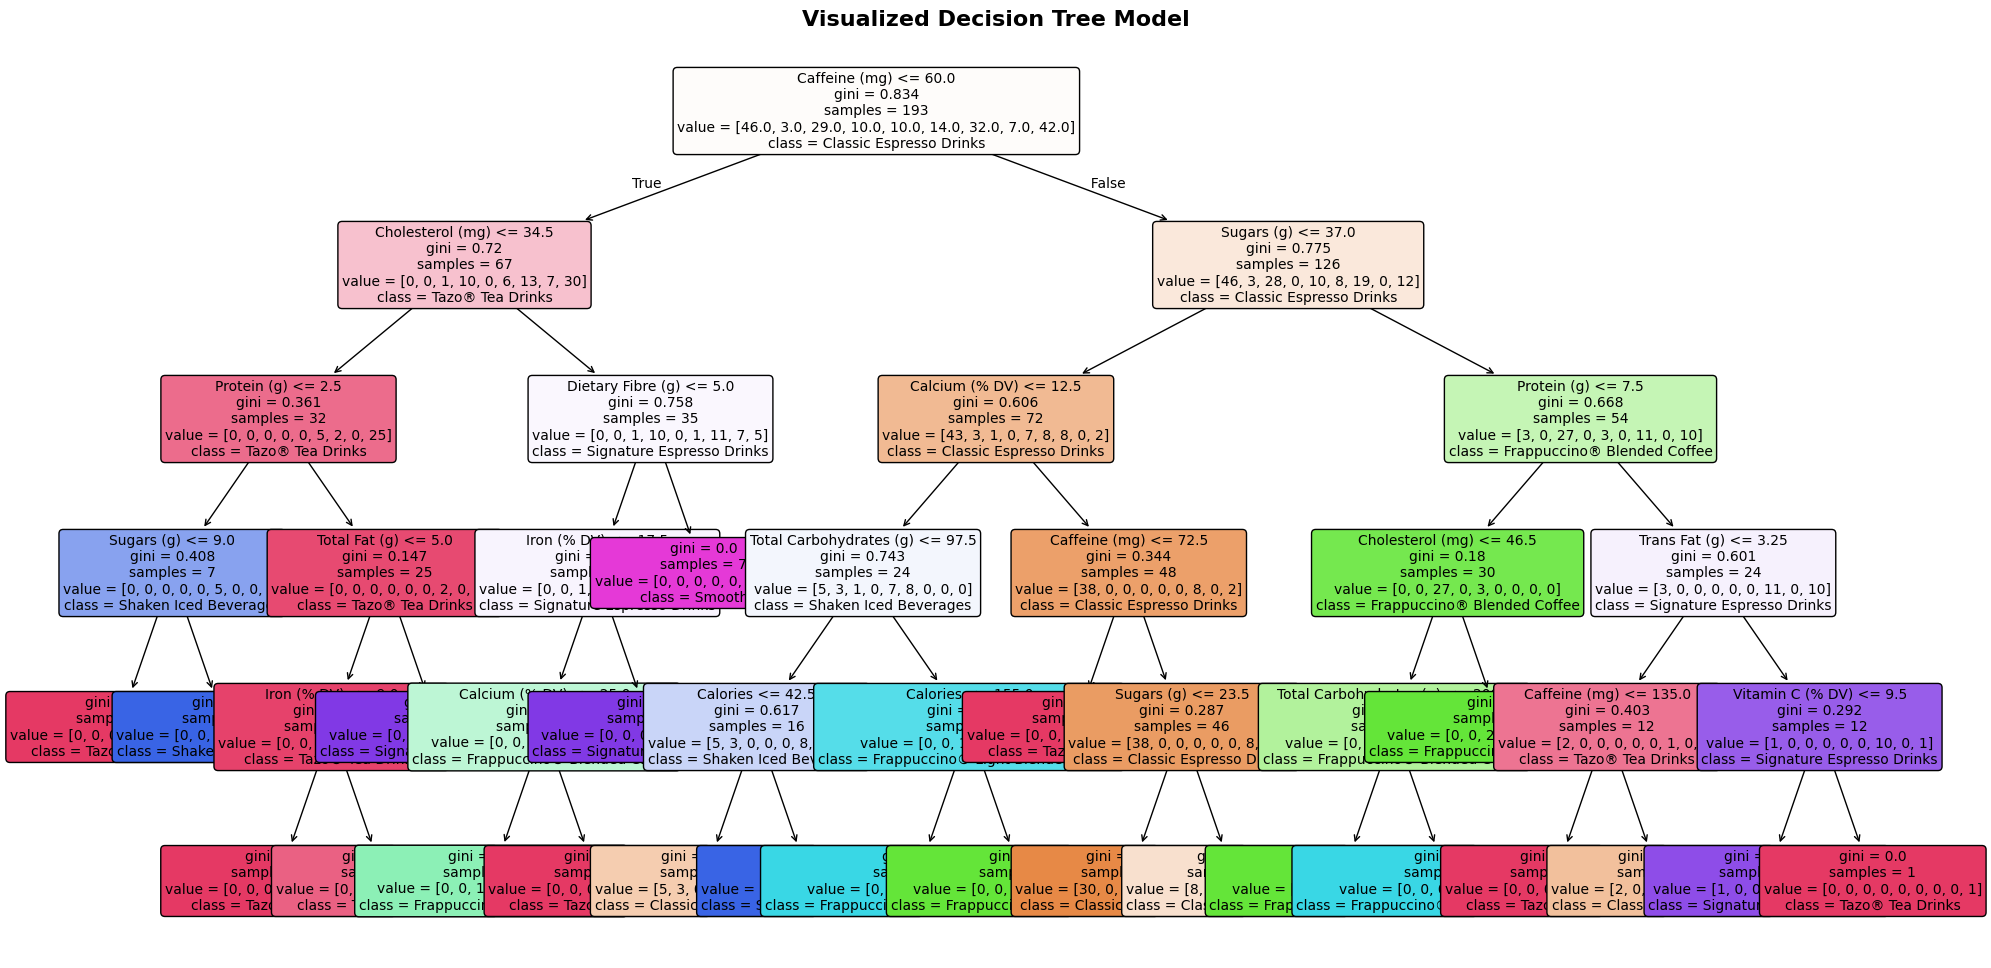

In [ ]:
# 7. Plot the Decision Tree structure
plt.figure(figsize=(24, 12))
plot_tree(
    clf,
    feature_names=feature_cols,
    class_names=list(le.classes_),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Visualized Decision Tree Model', fontsize=16, fontweight='bold')
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 7, 8, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}

# Initialize the Decision Tree model
base_clf = DecisionTreeClassifier(random_state=42)

# Initialize Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(estimator=base_clf, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Best parameters and best score during cross-validation
print("Best Parameters Found:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Best Parameters Found: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross-Validation Accuracy: 80.84%


In [ ]:
# Evaluate the optimized model on the test set
best_clf = grid_search.best_estimator_
y_opt_pred = best_clf.predict(X_test)

opt_accuracy = accuracy_score(y_test, y_opt_pred)
print(f"Optimized Decision Tree Test Accuracy: {opt_accuracy * 100:.2f}%")
print(f"Improvement over base model: {(opt_accuracy - accuracy) * 100:+.2f} percentage points\n")

print("--- Optimized Classification Report ---")
print(classification_report(y_test, y_opt_pred, target_names=le.classes_, zero_division=0))

Optimized Decision Tree Test Accuracy: 75.51%
Improvement over base model: +4.08 percentage points

--- Optimized Classification Report ---
                                   precision    recall  f1-score   support

          Classic Espresso Drinks       0.65      0.92      0.76        12
                           Coffee       1.00      1.00      1.00         1
      Frappuccino® Blended Coffee       0.75      0.86      0.80         7
       Frappuccino® Blended Crème       1.00      0.67      0.80         3
Frappuccino® Light Blended Coffee       0.00      0.00      0.00         2
            Shaken Iced Beverages       0.80      1.00      0.89         4
        Signature Espresso Drinks       0.67      0.25      0.36         8
                        Smoothies       1.00      1.00      1.00         2
                 Tazo® Tea Drinks       0.90      0.90      0.90        10

                         accuracy                           0.76        49
                        macro avg

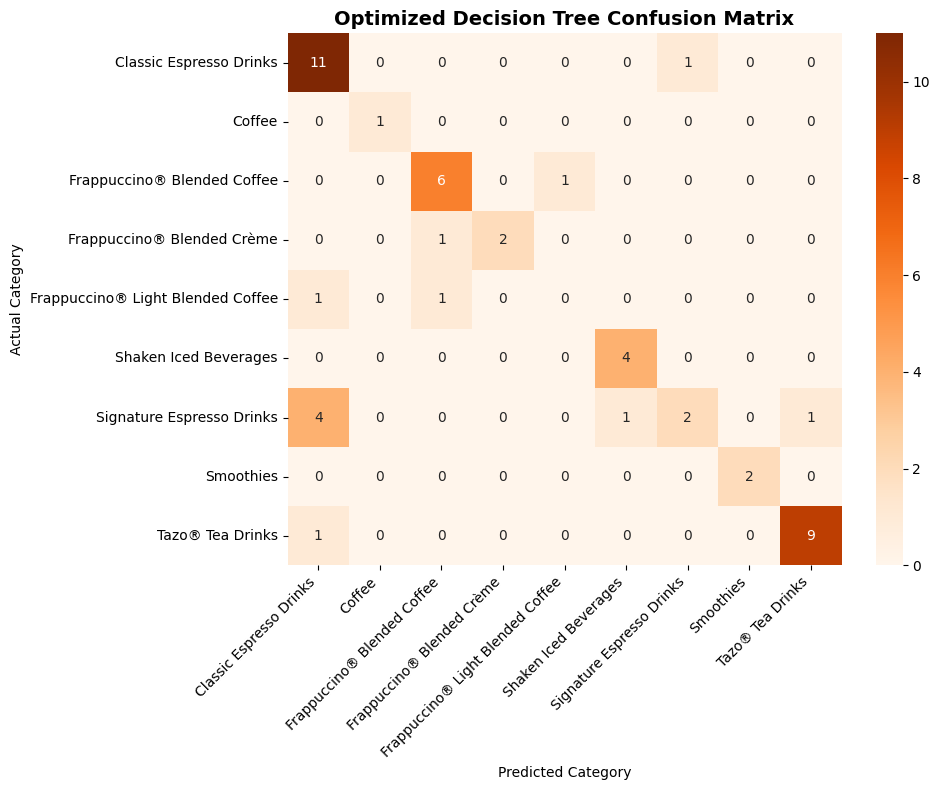

In [ ]:
# Visualize the new Confusion Matrix for the tuned model
opt_cm = confusion_matrix(y_test, y_opt_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(opt_cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Oranges')
plt.title('Optimized Decision Tree Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Select the first 10 samples from the test set
X_test_sample = X_test.head(10)
y_test_sample_encoded = y_test[:10]

# 2. Predict using our optimized model
y_pred_sample_encoded = best_clf.predict(X_test_sample)

# 3. Decode the numerical targets back to original beverage category names
actual_categories = le.inverse_transform(y_test_sample_encoded)
predicted_categories = le.inverse_transform(y_pred_sample_encoded)

# 4. Extract corresponding actual drink names from the original dataframe
sample_indices = X_test_sample.index
drink_names = df.loc[sample_indices, 'Beverage'].values
beverage_preps = df.loc[sample_indices, 'Beverage_prep'].values

# 5. Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Beverage Name': drink_names,
    'Beverage Prep': beverage_preps,
    'Actual Category': actual_categories,
    'Predicted Category': predicted_categories,
    'Correct Prediction': actual_categories == predicted_categories
})

display(comparison_df)

,Beverage Name,Beverage Prep,Actual Category,Predicted Category,Correct Prediction
0,Mocha (Without Whipped Cream),Whole Milk,Frappuccino® Blended Coffee,Frappuccino® Blended Coffee,True
1,Hot Chocolate (Without Whipped Cream),Soymilk,Signature Espresso Drinks,Signature Espresso Drinks,True
2,Caffè Americano,Grande,Classic Espresso Drinks,Classic Espresso Drinks,True
3,Vanilla Latte (Or Other Flavoured Latte),2% Milk,Classic Espresso Drinks,Classic Espresso Drinks,True
4,Tazo® Chai Tea Latte,2% Milk,Tazo® Tea Drinks,Tazo® Tea Drinks,True
5,Caffè Latte,2% Milk,Classic Espresso Drinks,Classic Espresso Drinks,True
6,Cappuccino,Soymilk,Classic Espresso Drinks,Classic Espresso Drinks,True
7,Iced Brewed Coffee (With Classic Syrup),Grande,Shaken Iced Beverages,Shaken Iced Beverages,True
8,Brewed Coffee,Grande,Coffee,Coffee,True
9,Caramel Macchiato,Short Nonfat Milk,Signature Espresso Drinks,Classic Espresso Drinks,False


In [ ]:
import pickle

# Save the best classifier and label encoder together
model_artifacts = {
    'model': best_clf,
    'label_encoder': le,
    'feature_names': feature_cols
}

model_path = '/content/starbucks_decision_tree_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_artifacts, f)

print(f"Model successfully saved to {model_path}!")

Model successfully saved to /content/starbucks_decision_tree_model.pkl!
